In [47]:
what_were_covering = {1: "data (prepare and load)",
    2: "build model",
    3: "fitting the model to data (training)",
    4: "making predictions and evaluating a model (inference)",
    5: "saving and loading a model",
    6: "putting it all together"
}

# A PyTorch Workflow[cite: 1]

1. **Get data ready (turn into tensors)**[cite: 1]
2. **Build or pick a pretrained model (to suit your problem)**[cite: 1]
   * **2.1 Pick a loss function & optimizer**[cite: 1]
   * **2.2 Build a training loop**[cite: 1]
3. **Fit the model to the data and make a prediction**[cite: 1]
4. **Evaluate the model**[cite: 1]
5. **Improve through experimentation**[cite: 1]
6. **Save and reload your trained model**[cite: 1]

---

```mermaid
flowchart LR
    A["1. Get data ready\n(turn into tensors)"] --> B["2. Build or pick a pretrained model\n(to suit your problem)"]
    B --> C["2.1 Pick a loss function & optimizer"]
    C --> D["2.2 Build a training loop"]
    D --> E["3. Fit the model to the data\and make a prediction"]
    E --> F["4. Evaluate the model"]
    F --> G["5. Improve through experimentation"]
    G --> H["6. Save and reload your trained model"]

In [48]:
import torch 
from torch import nn ## nn(neural netwoks) contains all PyTorch's building blocks for neural networks 
import matplotlib.pyplot as plt 

torch.__version__


'2.14.0'

# 1. Data (preparing and loading)

#### To learn how machine learning works from scratch, we need data. If we do not have a real dataset (like photos or spreadsheets), we can simply create our own.

In [49]:
# Create a "Known" Parameters

weight = 0.7
bias = 0.3

# create a data 
X = torch.arange(start=0,end= 1,step=0.02).unsqueeze(dim=1)

".unsqueeze(dim=1): Adds an extra dimension to turn the flat list into a vertical column shape.   "
"Without it, shape is [50].    With .unsqueeze(dim=1), shape becomes [50, 1]."
"Why? PyTorch layers expect inputs formatted as [batch_size, number_of_features],"
" so each number needs its own bracket: [[0.00], [0.02], [0.04], ...]"

y = weight * X + bias

X[:10],y[:10]


(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [50]:
## Creating a Train/Test split 
train_split = int(len(X)*0.8)
X_train, y_train = X[:train_split],y[:train_split]
X_test , y_test = X[train_split:],y[train_split:]

len(X_train),len(y_train),len(X_test),len(y_test)


(40, 40, 10, 10)

In [51]:
def plot_predictions(train_data = X_train,train_labels = y_train,test_data = X_test,test_labels = y_test,Predictions = None):

    plt.Figure(figsize=(10,7))
    plt.scatter(train_data,train_labels,c="b",s=4,label = "Training Data")
    plt.scatter(test_data,test_labels,c="g",s=4,label = "Testing Data")

    if Predictions is not None :
        plt.scatter(test_data,Predictions , c = "r", s = 4 , label = "Predictions")

    plt.legend(prop={"size" : 14 })    ;

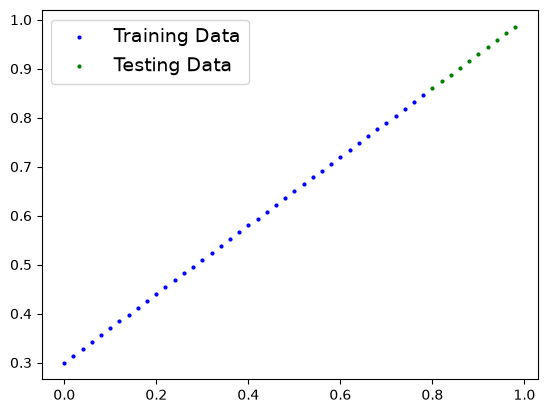

In [52]:
plot_predictions();

# 2. Build model

##### Now we've got some data, let's build a model to use the blue dots to predict the green dots.



In [53]:
class LinearRegressionModel(nn.Module): # # <- almost everything in PyTorch is a nn.Module (think of this as neural network lego blocks)
    
    def __init__(self): # start with random weights (this will get adjusted as the model learns)
        super().__init__()
        self.weights = nn.Parameter(torch.rand(1,dtype=torch.float),requires_grad=True)
        self.bias = nn.Parameter(torch.randn(1,dtype=torch.float),requires_grad= True)

    def forward(self,x:torch.Tensor) -> torch.tensor:
        return self.weights*x + self.bias    

## PyTorch model building essentials
### * PyTorch has four (give or take) essential modules you can use to create almost any kind of neural network you can imagine.
#### They are "torch.nn", "torch.optim", "torch.utils.data.Dataset" and "torch.utils.data.DataLoader". For now, we'll focus on the first two and get to the other two later (though you may be able to guess what they do).

* almost everything in a PyTorch neural network comes from "torch.nn".

* "nn.Module" contains the larger building blocks (layers)
* "nn.Parameter" contains the smaller parameters like weights and biases (put these together to make nn.Module(s))
* "forward()" tells the larger blocks how to make calculations on inputs (tensors full of data) within nn.Module(s)
* "torch.optim" contains optimization methods on how to improve the parameters within nn.Parameter to better represent input data

In [54]:
# Checking the contents of a PyTorch model

torch.manual_seed(19) # # Set manual seed since nn.Parameter are randomly initialized

#  Create an instance of the model (this is a subclass of nn.Module that contains nn.Parameter(s))
model_0 = LinearRegressionModel()

list(model_0.parameters()) # Check the nn.Parameter(s) within the nn.Module subclass we created

[Parameter containing:
 tensor([0.9686], requires_grad=True),
 Parameter containing:
 tensor([-0.6832], requires_grad=True)]

In [55]:
model_0.state_dict() #This asks the model: "Give me a dictionary of your current internal state and learned weights". 
# its give a a clean dictionary mapping each parameter's exact name to its current value.

OrderedDict([('weights', tensor([0.9686])), ('bias', tensor([-0.6832]))])

### Making predictions using "torch.inference_mode()".
#### it tells PyTorch: "While inside this indented block, do not track any gradients, do not record history for autograd, and run as fast and light as possible"


In [56]:
# Make Prediction with Model 
with torch.inference_mode(): # inference means making predictions
    y_preds = model_0(X_test)

## # Note: in older PyTorch code you might also see torch.no_grad() , now torch.no_grad() is replaced with torch.inference_mode() as it is more faster and safer .
# with torch.no_grad():
#   y_preds = model_0(X_test)    


In [57]:
# Check the predictions
print(f"Number of testing samples: {len(X_test)}") 
print(f"Number of predictions made: {len(y_preds)}")
print(f"Predicted values:\n{y_preds}")

Number of testing samples: 10
Number of predictions made: 10
Predicted values:
tensor([[0.0917],
        [0.1110],
        [0.1304],
        [0.1498],
        [0.1691],
        [0.1885],
        [0.2079],
        [0.2273],
        [0.2466],
        [0.2660]])


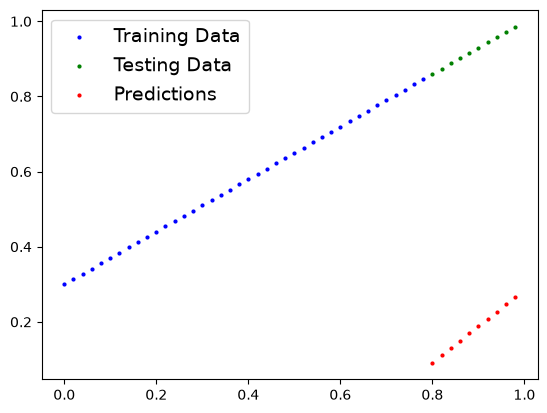

In [58]:
plot_predictions(Predictions=y_preds)

In [59]:
y_test-y_preds # Those predictions look pretty bad..., becoz they are just a random parameter values just to make predictions.without training model 

tensor([[0.7683],
        [0.7630],
        [0.7576],
        [0.7522],
        [0.7469],
        [0.7415],
        [0.7361],
        [0.7307],
        [0.7254],
        [0.7200]])

## 3).  Train Model 
##### Right now our model is making predictions using random parameters to make calculations, it's basically guessing (randomly).

#### To fix that, we can update its internal parameters (I also refer to parameters as patterns), the weights and bias values we set randomly using nn.Parameter() and torch.randn() to be something that better represents the data.


### # Creating a loss function and optimizer in PyTorch
#### - For our model to update its parameters on its own, we'll need to add a few more things to our recipe.

#### - And that's a loss function as well as an optimizer

In [60]:
# create a loss function 
Loss_fn = nn.L1Loss() # MAE Loss is as same as L1Loss

# create a optimizer 
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01)

### Creating an optimization loop in PyTorch

#### Now we've got a loss function and an optimizer, it's now time to create a training loop (and testing loop).

##### The training loop involves the model going through the training data and learning the relationships between the features and labels.

##### The testing loop involves going through the testing data and evaluating how good the patterns are that the model learned on the training data (the model never sees the testing data during training).

##### Each of these is called a "loop" because we want our model to look (loop through) at each sample in each dataset.



In [61]:
torch.manual_seed(19)

epochs = 100 # set the number of epochs( how many times the model will pass over the training data )

# create a empty loss lists to track values     
train_loss_values = []
test_loss_values = []
epochs_count = []

for epochs in range(epochs):
    ## Training 

    # put the model in training mode ( this is the default state of model)
    model_0.train()

    # 1. forward pass on train data using the forward() method inside 
    y_pred = model_0(X_train)
    # print y_pred

    # 2. calculate loss ( how different our model predict to the ground truth )
    
    loss = Loss_fn(y_pred,y_train)

    # 3. Zero grad of the optimizer 
    optimizer.zero_grad()

    # 4 . Loss backwards 
    loss.backward()

    # 5. progress the optimizer 
    optimizer.step()

    #### Testing 

    # put the model in evaluation mode 
    model_0.eval()

    with torch.inference_mode():

        ## 1. Forward pass on the test data 
        test_pred = model_0(X_test)


        # 2. calculate loss on test data 
        test_loss = loss_fn(test_pred, y_test.type(torch.float))

        if epochs % 10 == 0 :
            epochs_count.append(epochs)
            train_loss_values.append(loss.detach().numpy())
            test_loss_values.append(test_loss.detach().numpy())
            print(f"epoch: {epochs} | MAE Train Loss : {loss} | MAE Test Loss : {test_loss}")





epoch: 0 | MAE Train Loss : 0.8784680366516113 | MAE Test Loss : 0.7306956052780151
epoch: 10 | MAE Train Loss : 0.7632580995559692 | MAE Test Loss : 0.5959855914115906
epoch: 20 | MAE Train Loss : 0.6480480432510376 | MAE Test Loss : 0.46127527952194214
epoch: 30 | MAE Train Loss : 0.532837986946106 | MAE Test Loss : 0.3265649080276489
epoch: 40 | MAE Train Loss : 0.41762781143188477 | MAE Test Loss : 0.1918545514345169
epoch: 50 | MAE Train Loss : 0.3024176061153412 | MAE Test Loss : 0.05714409425854683
epoch: 60 | MAE Train Loss : 0.18764783442020416 | MAE Test Loss : 0.0767192393541336
epoch: 70 | MAE Train Loss : 0.13215167820453644 | MAE Test Loss : 0.15816567838191986
epoch: 80 | MAE Train Loss : 0.11478371918201447 | MAE Test Loss : 0.19641044735908508
epoch: 90 | MAE Train Loss : 0.10710220038890839 | MAE Test Loss : 0.21414056420326233


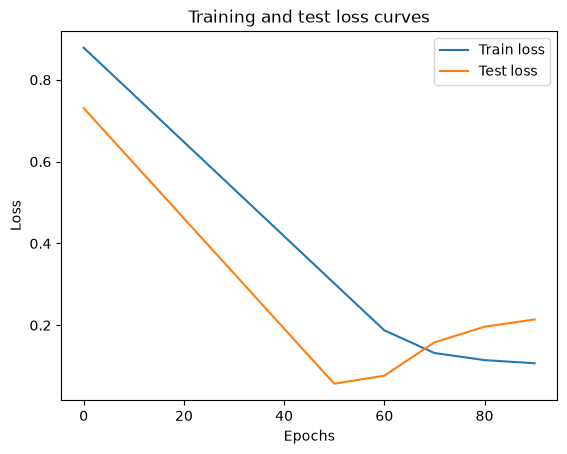

In [62]:
# Plot the loss curves
plt.plot(epochs_count, train_loss_values, label="Train loss")
plt.plot(epochs_count, test_loss_values, label="Test loss")
plt.title("Training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend();

In [38]:
# Find our model's learned parameters
print("The model learned the following values for weights and bias:")
print(model_0.state_dict())
print("\nAnd the original values for weights and bias are:")
print(f"weights: {weight}, bias: {bias}")

The model learned the following values for weights and bias:
OrderedDict({'weights': tensor([1.2002]), 'bias': tensor([0.0743])})

And the original values for weights and bias are:
weights: 0.7, bias: 0.3


## 4. Making predictions with a trained PyTorch model (inference)


In [39]:
# 1). set model evaluation mode 
model_0.eval()

# 2). setup the inference mode context manager 

with torch.inference_mode():
      # 3. Make sure the calculations are done with the model and data on the same device

      # in our case, we haven't setup device-agnostic code yet so our data and model are
      # on the CPU by default.
      # model_0.to(device)
      # X_test = X_test.to(device)


      y_preds = model_0(X_test)
y_preds      



tensor([[1.0345],
        [1.0585],
        [1.0825],
        [1.1065],
        [1.1305],
        [1.1545],
        [1.1785],
        [1.2025],
        [1.2265],
        [1.2505]])

##### We've made some predictions with our trained model, now how do they look?

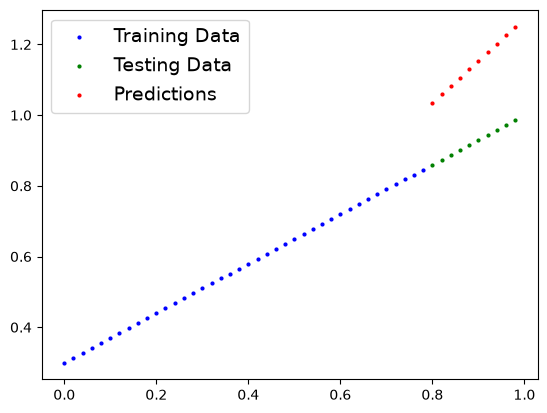

In [40]:
plot_predictions(Predictions=y_preds)

#### Those red dots are looking far closer than they were before!

#### Let's get onto saving and reloading a model in PyTorch.



## 5. Saving and loading a PyTorch model

#### This section covers how to serialize and write your trained model to disk so you do not lose the learned weights when shutting down Python.

In [ ]:
# 1. Creating the Destination Folder
from pathlib import Path

Model_path = Path("models") # Path("models"): Uses Python’s object-oriented pathlib module to specify a target directory named models

Model_path.mkdir(parents=True, exist_ok=True) # mkdir(parents=True, exist_ok=True): Creates the directory on your storage drive.

                                              #  parents=True: Creates any missing parent folders in the path.

                                              #  exist_ok=True: Prevents Python from throwing a FileExistsError if the folder already exists."

In [ ]:
# 2. Building the Target Filepath
Model_Name = "01_pytorch_workflow_model_0.pth"  # By convention in PyTorch, weight checkpoints end with either .pt or .pth.

Model_Save_Path = Model_path / Model_Name       # The / operator here combines the directory path with the filename into a cross-platform 
                                                # path: models/01_pytorch_workflow_model_0.pth.

In [44]:
# 3. Writing state_dict() to Disk
print(f"Saving model to : {Model_Save_Path}")

torch.save(obj=model_0.state_dict(),f=Model_Save_Path)
# obj=model_0.state_dict(): Crucially, we do not pass model_0 directly. We only pass model_0.state_dict(),
#  which is a clean dictionary containing the parameter tensors (weights and bias).

#  f=MODEL_SAVE_PATH: The destination path where the binary file is created.

Saving model to : models/01_pytorch_workflow_model_0.pth


In [45]:
# Check the saved file path
!ls -l models/01_pytorch_workflow_model_0.pth

-rw-r--r--@ 1 amitkumar  staff  2117 Oct 20 11:42 models/01_pytorch_workflow_model_0.pth


### Loading a saved PyTorch model's state_dict()

In [46]:
loaded_model_0 = LinearRegressionModel()


loaded_model_0.load_state_dict(torch.load(f=Model_Save_Path))

<All keys matched successfully>

In [65]:
# 1. Update y_preds using the trained model_0
model_0.eval()
with torch.inference_mode():
    y_preds = model_0(X_test)

# 2. Make predictions with the loaded model
loaded_model_0.eval()
with torch.inference_mode():
    loaded_model_preds = loaded_model_0(X_test)

# 3. Compare them
y_preds == loaded_model_preds

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])